# Make your own weather forecast map 🌡️
### ECMWF free & open data · 9 km · over Hungary

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/hungary_forecast.ipynb)

Everything here uses **free, open data** from ECMWF and the open-source **earthkit** libraries. In a few cells you'll
pull today's **9 km** forecast with **earthkit-data** and draw a map of **temperature over Hungary** with **earthkit-plots**.

Then change one line and make it for **your** country, day, or variable.

*In Google Colab? Press **Runtime → Run all**. Nothing to install on your own computer.*

In [55]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q earthkit

In [56]:
import numpy as np
import matplotlib.patheffects as pe
import earthkit.data as ekd
import earthkit.plots as ekp

## 1 · Choose what to map

`DATE = 0` means **today's** forecast. `STEP` is how many hours ahead.
Change `COUNTRY`, `CAPITAL`, or `STEP` and re-run to make a different map.

In [57]:
COUNTRY = "Hungary"
CAPITAL = ("Budapest", 47.498, 19.04)        # name, lat, lon
DATE    = 0                                # 0 = today's 00Z run
STEP    = 180                               # hours ahead
PARAM   = "2t"                             # 2 m temperature

## 2 · Get the forecast (ECMWF open data, 9 km)

**earthkit-data** has the ECMWF open-data service built in as a *source*. `resol="0p1"` is the
important bit — it asks for the 0.1° (~9 km) data; the default is coarser (0.25°).

The result is a *fieldlist*: we pick the field we asked for and look at what's in it.

In [58]:
ds = ekd.from_source("ecmwf-open-data", date=DATE, time=0, step=STEP, stream="oper",
                     type="fc", levtype="sfc", param=PARAM, resol="0p1")

fields = ds.to_fieldlist()
field = fields[0]
fields.ls()

,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,2t,2026-11-09 12:00:00,2026-11-02,7 days 12:00:00,2,height_above_ground_level,None,regular_ll


In [59]:
print(f"{field.metadata('shortName')} on a {field.shape[1]} x {field.shape[0]} global grid, "
      f"valid {field.metadata('valid_datetime')}")

2t on a 3600 x 1801 global grid, valid 2026-11-09 12:00:00


## 3 · Draw the map

**earthkit-plots** does the map projection, borders and colour legend for us. We give it
the field, a `domain` (just the country name!) and a style that converts kelvin to °C.

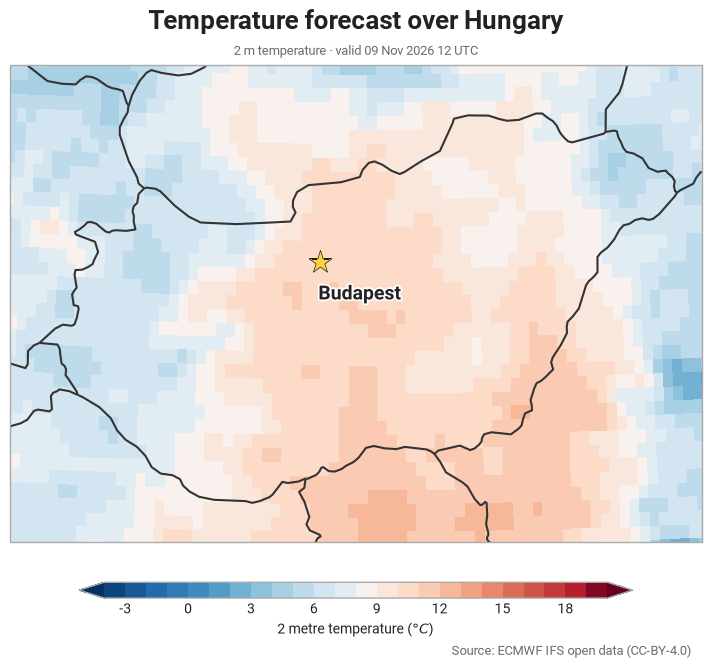

In [60]:
# Colour scale in whole degrees C (kelvin is converted for us)
style = ekp.styles.Style(
    levels=np.arange(-4, 21, 1),             # change to suit your season / country
    extend="both",
    colors="RdBu_r",
    units="celsius",
    units_label="°C",
)

#TEXT = "white"                               # text colour for dark background
#SUBTEXT = "#c8c8c8"                        # subtitle / source colour for dark background
TEXT = "#222222"                           # text colour for light background
SUBTEXT = "#6b6b6b"                        # subtitle / source colour for light background

chart = ekp.Map(domain=COUNTRY)
chart.pcolormesh(field, style=style)
chart.borders(linewidth=1.5, color="#333333")
chart.coastlines()

name, clat, clon = CAPITAL
chart.scatter(x=[clon], y=[clat], marker="*", s=300, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
chart.text(clon, clat + 0.12, name, ha="center", va="bottom", fontsize=14, fontweight="bold",
           color="#222222", zorder=11, path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

valid = field.metadata("valid_datetime")
chart.title(f"Temperature forecast over {COUNTRY}", fontsize=19, fontweight="bold", pad=26, color=TEXT)
chart.ax.text(0.5, 1.015, f"2 m temperature · valid {valid:%d %b %Y %H UTC}", transform=chart.ax.transAxes,
              ha="center", va="bottom", color=SUBTEXT, fontsize=9)
legend = chart.legend(location="bottom")
for cbar_ax in chart.fig.axes[1:]:           # colour bar: labels and tick numbers
    cbar_ax.xaxis.label.set_color(TEXT)
    cbar_ax.tick_params(colors=TEXT)
chart.fig.text(0.98, -0.02, "Source: ECMWF IFS open data (CC-BY-4.0)", ha="right", color=SUBTEXT, fontsize=9)
chart.fig.savefig(f"{COUNTRY.lower()}_map.png", dpi=140, bbox_inches="tight", transparent=True)
chart.show()

## 4 · Your turn 🌍

- **Different country?** Change `COUNTRY` and `CAPITAL`, then Run all. `ekp.Map(domain=...)` understands country names.
- **Different day?** Change `STEP` (24, 72, 120 …).
- **Different weather?** Try `PARAM = "tp"` for rainfall (use a different `Style`: metres → `units="mm"`),
  or `"10u"`/`"10v"` for wind.
- **Different look?** Swap `chart.pcolormesh` for `chart.contourf` to get a smoother plot instead of the individual 9 km grid cells.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) ·
[earthkit-data](https://earthkit-data.readthedocs.io) ·
[earthkit-plots](https://earthkit-plots.readthedocs.io) ·
[ecmwf-opendata](https://github.com/ecmwf/ecmwf-opendata)